# 06 - Visual results

##### The confusion matrix as a heatmap

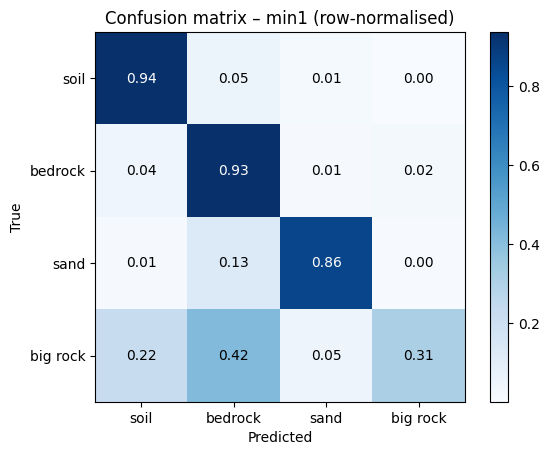

In [1]:
import sys
sys.path.append("..")
import torch 
import matplotlib.pyplot as plt 
from matplotlib.colors import ListedColormap 
from matplotlib.patches import Patch
from PIL import Image 
import numpy as np 
from pathlib import Path 
import json
from src.evaluate import load_model
from src.dataset import MarsTerrainDataset, build_pairs
from src.metrics import confusion_matrix, iou_from_confusion

with open('../results/run1_256/results.json', 'r') as f:
    results = json.load(f) # a dict 
    # normalise each row (divide by the row sum)
    cm = np.array(results["min1"]["confusion_matrix"])
    normalized = cm / cm.sum(axis=1, keepdims=True)

classes = ["soil", "bedrock", "sand", "big rock"]
plt.imshow(normalized, cmap="Blues")
plt.colorbar()
plt.xticks(range(4), classes)
plt.yticks(range(4), classes)
plt.xlabel("Predicted")
plt.ylabel("True")
# x (column) first, then y (row)
# one text per cell, 16 in total
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{normalized[i, j]:.2f}", ha="center", va="center", color="white" if normalized[i, j] > 0.5 else "black") 
plt.title("Confusion matrix – min1 (row-normalised)")
plt.savefig('../results/run1_256/confusion_min1.png', dpi=150, bbox_inches="tight")
plt.show()

Each row says: of all pixels that truly are this class, what fraction got predicted as each class? The diagonal is the per-class recall (how much of each class the model finds).
- Soil 0.94 and bedrock 0.93: found almost completely.
- Sand 0.86: the main mistake is sand → bedrock (13%), probably where thin sand lies on rock.
- Big rock 0.31: only about a third is found. 42% is predicted as bedrock and 22% as soil. It’s mostly confused with bedrock, since both are rock and the difference is mainly size and shape.

**Why big rock IoU is so low:**

Recall is 0.31, but IoU on min1 was only 0.079. IoU also punishes false positives: pixels wrongly predicted as big rock. Look at the bedrock row: 2% of bedrock pixels are predicted as big rock. That sounds small, but bedrock has many more pixels than big rock, so that 2% is a large number of wrong big-rock predictions, more than the correctly found big-rock pixels. So the model doesn’t only miss big rocks; it also places big rocks in the wrong spots on bedrock.

#### Predictions on test images 

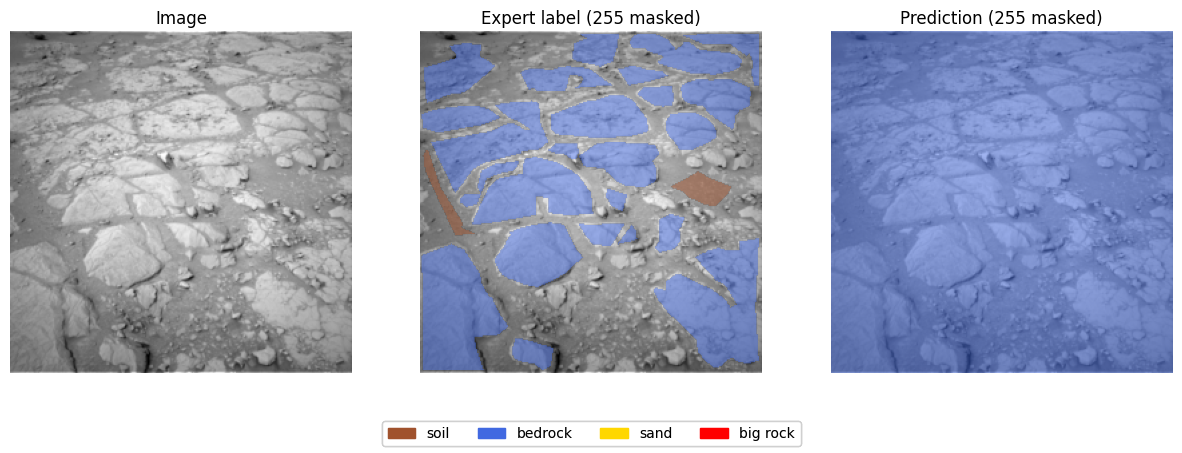

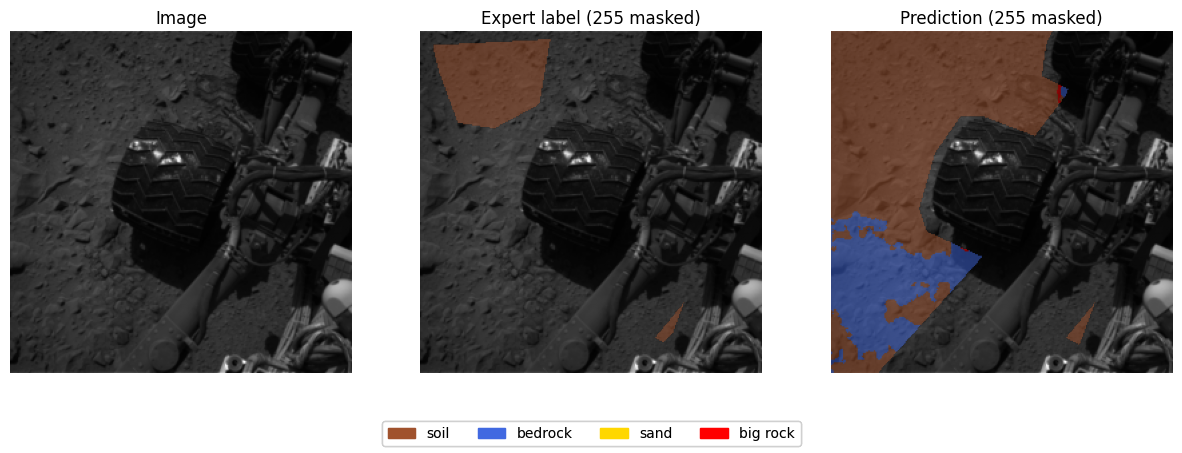

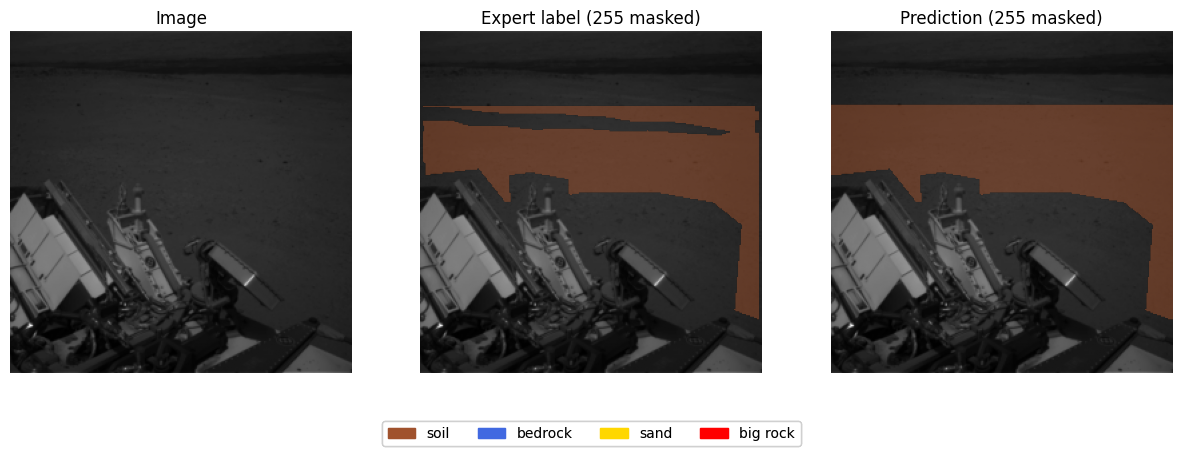

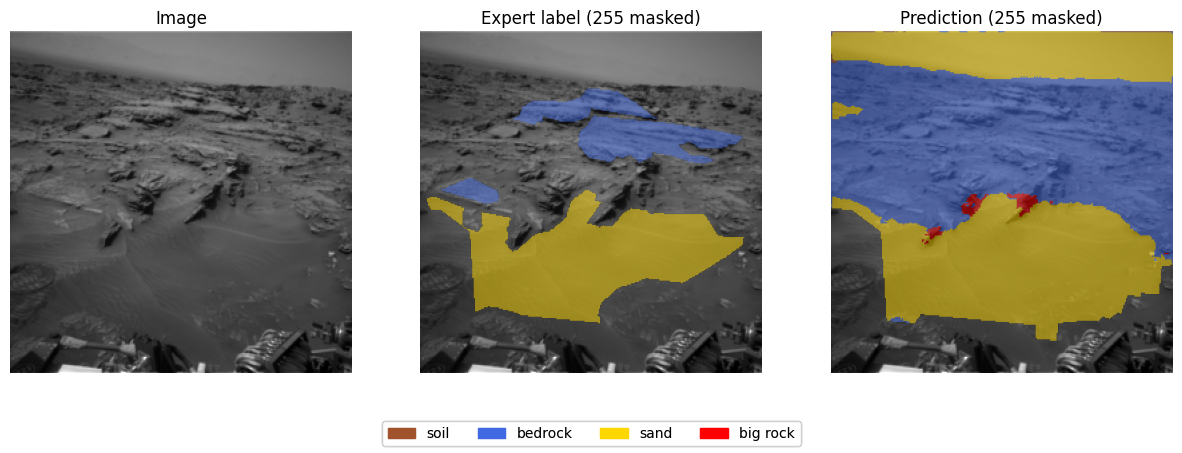

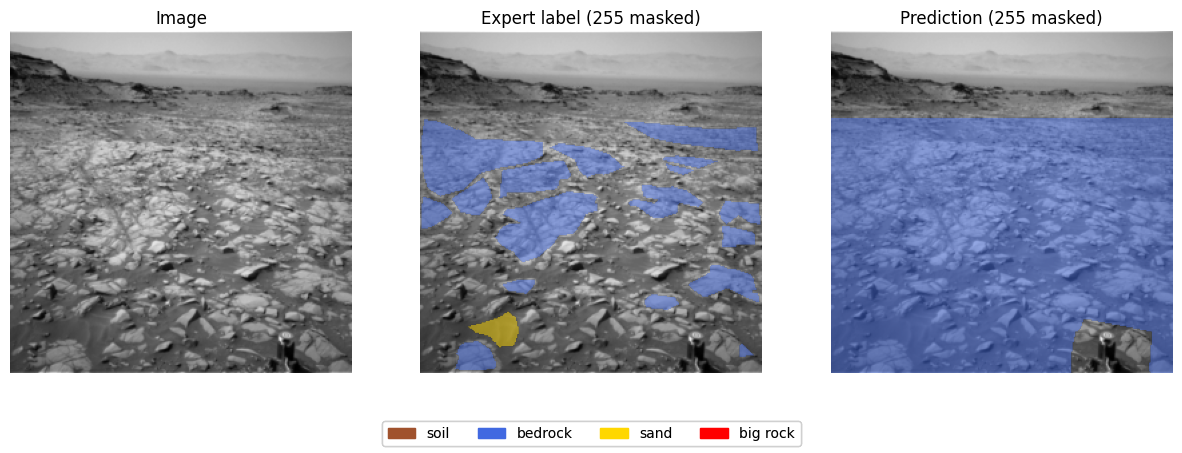

In [6]:
model = load_model("../outputs/run1_256/best.pth", torch.device("cpu"))

DATA_DIR = Path(r"C:\data-mars\msl\ncam")
IMG_DIR = DATA_DIR / "images" / "edr"
ROVER_DIR = DATA_DIR / "images" / "mxy"
RANGE_DIR = DATA_DIR / "images" / "rng-30m"
TEST_DIR = DATA_DIR / "labels" / "test" / "masked-gold-min3-100agree"

test_pairs = build_pairs(IMG_DIR, TEST_DIR)       
test_ds = MarsTerrainDataset(test_pairs, size=256)   
colors = ["sienna", "royalblue", "gold", "red"]
classes = ["soil", "bedrock", "sand", "big rock"]
cmap = ListedColormap(colors) 
legend_items = [Patch(color=c, label=n) for c, n in zip(colors, classes)]

# for each chosen index i:
# get the image and label from the dataset
# predict 
# load the two masks for that image, resize them to 256 (nearest), and hide the prediction where they’re 1
# plot image | label | masked prediction
for n, i in enumerate([0, 40, 80, 120, 160]):
    img, lbl = test_ds[i]
    with torch.no_grad(): # no gradients 
        # the model expects a batch, so add a batch dimension with .unsqueeze(0), then take the argmax and the first item
        pred = model(img.unsqueeze(0)).argmax(dim=1)[0].numpy()

    # masks, same stem as the image, with EDR → MXY / RNG
    stem = test_pairs[i][0].stem # test_pairs[i][0] is the image path of pair i
    for mask_dir, code in [(ROVER_DIR, "MXY"), (RANGE_DIR, "RNG")]:
        mask_path = mask_dir / (stem.replace("EDR", code) + ".png")
        if mask_path.exists():
            with Image.open(mask_path) as m:
                mask = np.array(m.resize((256, 256), Image.NEAREST))
            pred[mask==1] = 255       # hide the prediction where mask == 1
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5)) # a new figure per example 

    axes[0].imshow(img[0], cmap="gray")
    axes[0].set_title("Image")

    axes[1].imshow(img[0], cmap="gray")
    axes[1].imshow(np.ma.masked_equal(lbl.numpy(), 255), cmap=cmap, vmin=0, vmax=3, alpha=0.5)
    axes[1].set_title("Expert label (255 masked)")

    axes[2].imshow(img[0], cmap="gray") 
    axes[2].imshow(np.ma.masked_equal(pred, 255), cmap=cmap, vmin=0, vmax=3, alpha=0.5)
    axes[2].set_title("Prediction (255 masked)")

    for ax in axes:
        ax.axis("off") 
        fig.legend(handles=legend_items, loc="lower center", ncol=4)
    if n < 3: # save the first 3 examples 
        plt.savefig(f"../results/run1_256/example_{n + 1}.png", dpi=150, bbox_inches="tight")
    plt.show()

#### Failure gallery 

#### Findings 